# Pixel embedding resource analysis

Parse every request recorded in `pixellogs/*.txt` and compare the three embedding inputs: **image**, **text** (logged as JSON only), and **image+text** (logged as Image + JSON).

A run is usable only when all three embedding requests completed. `pixel.py` writes a `[RUN INVALID]` notice when any request fails, and the parser excludes the entire log rather than retaining its other modalities. For compatibility, legacy logs with a non-2xx HTTP status, a nonzero exit code, or an incomplete request set are excluded too. Missing memory fields remain `NaN`, so otherwise-valid older logs still contribute to time and power statistics.

In [1]:
from pathlib import Path
import re

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from IPython.display import display

sns.set_theme(style="whitegrid", context="notebook")
pd.set_option("display.max_columns", 50)
pd.set_option("display.width", 140)

LOG_DIR = Path("pixellogs")
EMBEDDING_ORDER = ["image", "text", "image+text"]
LABEL_TO_TYPE = {
    "Image only": "image",
    "JSON only": "text",
    "Image + JSON": "image+text",
}


## Parser

Parsing is request-section based because the detailed sections contain the newer RSS fields. Validity is file-wide: any `[RUN INVALID]` notice or incomplete/failed request excludes all modalities in that log. `VmHWM` is the process-lifetime resident-set high-water mark; the log labels make clear that it includes model startup as well as the request.

In [2]:
NUMBER = r"([-+]?(?:\d+(?:\.\d*)?|\.\d+)(?:[eE][-+]?\d+)?)"
REQUEST_RE = re.compile(
    r"^=== Request\s+\d+/\d+:\s*(.*?)\s*===\s*$",
    re.MULTILINE,
)

# Patterns are deliberately tied to units so that the two Energy consumption
# lines (mWh and J) cannot be confused with one another.
NUMERIC_FIELDS = {
    "embedding_dimensions": rf"^\[RESULT\] Embedding dimensions:\s*{NUMBER}\s*$",
    "response_time_s": rf"^\[RESULT\] Response time:\s*{NUMBER}\s*seconds\s*$",
    "charge_used_uah": rf"^\[RESULT\] Battery charge used:\s*{NUMBER}\s*microamp-hours\s*$",
    "mean_voltage_v": rf"^\[RESULT\] Mean battery voltage:\s*{NUMBER}\s*V\s*$",
    "energy_mwh": rf"^\[RESULT\] Energy consumption:\s*{NUMBER}\s*mWh\s*$",
    "energy_j": rf"^\[RESULT\] Energy consumption:\s*{NUMBER}\s*J\s*$",
    "average_power_w": rf"^\[RESULT\] Average power:\s*{NUMBER}\s*W\s*$",
    "current_before_ma": rf"^\[RESULT\] Battery current before:\s*{NUMBER}\s*mA\s*$",
    "current_after_ma": rf"^\[RESULT\] Battery current after:\s*{NUMBER}\s*mA\s*$",
    "rss_before_mib": rf"^\[RESULT\] Process RSS before request:\s*{NUMBER}\s*MiB(?:\s*\[PID\s+\d+\])?\s*$",
    "rss_after_mib": rf"^\[RESULT\] Process RSS after request:\s*{NUMBER}\s*MiB(?:\s*\[PID\s+\d+\])?\s*$",
    "peak_rss_mib": rf"^\[RESULT\] Process peak RSS \(startup \+ request, VmHWM\):\s*{NUMBER}\s*MiB(?:\s*\[PID\s+\d+\])?\s*$",
}
NUMERIC_FIELDS = {
    name: re.compile(pattern, re.MULTILINE)
    for name, pattern in NUMERIC_FIELDS.items()
}
METHOD_RE = re.compile(
    r"^\[RESULT\] Measurement method:\s*(.+?)\s*$", re.MULTILINE
)
RUN_ID_RE = re.compile(r"^Run ID:\s*(\d+)\s*$", re.MULTILINE)
STARTED_RE = re.compile(r"^Started:\s*(.+?)\s*$", re.MULTILINE)
EXIT_RE = re.compile(r"^Exit code:\s*(-?\d+)\s*$", re.MULTILINE)
HTTP_STATUS_RE = re.compile(r"^\[HTTP\] Status code:\s*(\d+)\s*$", re.MULTILINE)
INVALID_NOTICE_RE = re.compile(r"^\[RUN INVALID\].*$", re.MULTILINE)


def _numeric_value(pattern, section):
    match = pattern.search(section)
    return float(match.group(1)) if match else np.nan


def read_log_text(path):
    """Decode PowerShell UTF-16 logs and ordinary UTF-8 logs."""
    raw = path.read_bytes()
    if raw.startswith((b"\xff\xfe", b"\xfe\xff")):
        return raw.decode("utf-16", errors="replace")
    return raw.decode("utf-8-sig", errors="replace")


def parse_pixel_log(path):
    """Return (request rows, log metadata) parsed from one Pixel log."""
    text = read_log_text(path)
    run_match = RUN_ID_RE.search(text)
    run_id = int(run_match.group(1)) if run_match else (
        int(path.stem) if path.stem.isdigit() else path.stem
    )
    started_match = STARTED_RE.search(text)
    exit_match = EXIT_RE.search(text)
    headings = list(REQUEST_RE.finditer(text))
    invalid_notice = INVALID_NOTICE_RE.search(text)
    http_statuses = [int(value) for value in HTTP_STATUS_RE.findall(text)]

    metadata = {
        "run_id": run_id,
        "log_file": path.name,
        "started": started_match.group(1) if started_match else None,
        "exit_code": int(exit_match.group(1)) if exit_match else pd.NA,
        "has_summary": "=== Summary ===" in text,
        "request_sections": len(headings),
        "invalid_notice": invalid_notice.group(0) if invalid_notice else None,
    }

    rows = []
    for index, heading in enumerate(headings):
        end = headings[index + 1].start() if index + 1 < len(headings) else len(text)
        section = text[heading.end():end]
        raw_label = heading.group(1).strip()
        row = {
            "run_id": run_id,
            "log_file": path.name,
            "request_number": index + 1,
            "request_label": raw_label,
            "embedding_type": LABEL_TO_TYPE.get(raw_label, raw_label.lower()),
            "log_has_summary": metadata["has_summary"],
            "log_exit_code": metadata["exit_code"],
        }
        row.update({
            name: _numeric_value(pattern, section)
            for name, pattern in NUMERIC_FIELDS.items()
        })
        method_match = METHOD_RE.search(section)
        row["measurement_method"] = (
            method_match.group(1).strip() if method_match else None
        )
        required = ("response_time_s", "energy_mwh", "average_power_w")
        row["request_complete"] = all(pd.notna(row[field]) for field in required)
        row["rss_delta_mib"] = (
            row["rss_after_mib"] - row["rss_before_mib"]
            if pd.notna(row["rss_after_mib"]) and pd.notna(row["rss_before_mib"])
            else np.nan
        )
        rows.append(row)

    metadata["complete_requests"] = sum(row["request_complete"] for row in rows)
    expected_labels = set(LABEL_TO_TYPE)
    observed_labels = {row["request_label"] for row in rows}
    complete_request_set = (
        len(rows) == len(expected_labels)
        and observed_labels == expected_labels
        and all(row["request_complete"] for row in rows)
    )
    exit_code = metadata["exit_code"]
    if invalid_notice:
        invalid_reason = invalid_notice.group(0)
    elif any(status < 200 or status >= 300 for status in http_statuses):
        invalid_reason = f"legacy non-2xx HTTP status: {http_statuses}"
    elif pd.notna(exit_code) and exit_code != 0:
        invalid_reason = f"legacy nonzero exit code: {exit_code}"
    elif rows and not complete_request_set:
        invalid_reason = "incomplete three-request set"
    else:
        invalid_reason = None
    metadata["run_invalid"] = invalid_reason is not None
    metadata["invalid_reason"] = invalid_reason
    return rows, metadata


In [3]:
if not LOG_DIR.is_dir():
    raise FileNotFoundError(f"Pixel log directory not found: {LOG_DIR.resolve()}")

def log_sort_key(path):
    return (0, int(path.stem)) if path.stem.isdigit() else (1, path.name)

request_rows = []
log_rows = []
for log_path in sorted(LOG_DIR.glob("*.txt"), key=log_sort_key):
    rows, metadata = parse_pixel_log(log_path)
    if not metadata["run_invalid"]:
        request_rows.extend(rows)
    log_rows.append(metadata)

all_requests = pd.DataFrame(request_rows)
logs = pd.DataFrame(log_rows)
measurements = all_requests.loc[all_requests["request_complete"]].copy()
measurements["embedding_type"] = pd.Categorical(
    measurements["embedding_type"], categories=EMBEDDING_ORDER, ordered=True
)
measurements = measurements.sort_values(["run_id", "embedding_type"]).reset_index(drop=True)

print(f"Log files: {len(logs):,}")
print(f"Accepted request sections: {len(all_requests):,}")
print(f"Usable completed requests: {len(measurements):,}")
print(f"Invalid log files excluded: {logs['run_invalid'].sum():,}")


Log files: 292
Accepted request sections: 855
Usable completed requests: 855
Invalid log files excluded: 4


## Data-quality and coverage audit

Counts are shown separately for each metric because memory was added later. Every included run has a complete image, text, and image+text request; logs marked invalid (including legacy failures inferred by the parser) contribute no measurements.

In [4]:
coverage = (
    measurements.groupby("embedding_type", observed=False)
    .agg(
        requests=("run_id", "size"),
        time_n=("response_time_s", "count"),
        energy_n=("energy_mwh", "count"),
        power_n=("average_power_w", "count"),
        rss_before_n=("rss_before_mib", "count"),
        rss_after_n=("rss_after_mib", "count"),
        peak_rss_n=("peak_rss_mib", "count"),
    )
)
display(coverage)

invalid_logs = logs.loc[logs["run_invalid"]]
if not invalid_logs.empty:
    print("Invalid logs (all request sections excluded from analysis):")
    display(invalid_logs[["run_id", "log_file", "invalid_reason"]])

no_request_logs = logs.loc[logs["request_sections"] == 0]
if not no_request_logs.empty:
    print("Logs with no request section (for example, skipped inputs):")
    display(no_request_logs[["run_id", "log_file", "has_summary", "exit_code"]])


,requests,time_n,energy_n,power_n,rss_before_n,rss_after_n,peak_rss_n
embedding_type,,,,,,,
image,285,285,285,285,140,140,140
text,285,285,285,285,140,140,140
image+text,285,285,285,285,140,140,140


Invalid logs (all request sections excluded from analysis):


,run_id,log_file,invalid_reason
148,150,150.txt,"legacy non-2xx HTTP status: [200, 400]"
152,154,154.txt,"legacy non-2xx HTTP status: [200, 400]"
160,162,162.txt,[RUN INVALID] Image + JSON failed; exclude thi...
291,293,293.txt,[RUN INVALID] Image + JSON failed; exclude thi...


Logs with no request section (for example, skipped inputs):


,run_id,log_file,has_summary,exit_code
89,90,90.txt,False,<NA>
90,91,91.txt,False,<NA>
92,93,93.txt,False,<NA>


## Descriptive statistics

Energy (`mWh` or `J`) answers how much battery energy one embedding consumed. Average power (`W`) is energy divided by response time and answers the rate of draw during that request. Both are reported because a slower request can consume more total energy even at lower average wattage.

In [5]:
STAT_COLUMNS = ["count", "mean", "std", "min", "25%", "50%", "75%", "max"]

def descriptive_table(frame, metrics):
    """Tidy groupwise describe() output for {column: display label}."""
    tables = []
    for column, label in metrics.items():
        table = (
            frame.groupby("embedding_type", observed=False)[column]
            .describe(percentiles=[0.25, 0.5, 0.75])[STAT_COLUMNS]
            .reset_index()
        )
        table.insert(0, "metric", label)
        tables.append(table)
    return pd.concat(tables, ignore_index=True).set_index(["metric", "embedding_type"])

performance_metrics = {
    "response_time_s": "Response time (s)",
    "energy_mwh": "Energy (mWh / embedding)",
    "energy_j": "Energy (J / embedding)",
    "average_power_w": "Average power (W)",
}
performance_stats = descriptive_table(measurements, performance_metrics)
display(performance_stats.round(3))


count     mean      std      min      25%      50%      75%       max
metric                   embedding_type                                                                       
Response time (s)        image           285.0   66.835    4.705   49.929   64.217   65.682   67.916    80.859
                         text            285.0   31.276   37.004    0.884    9.150   19.712   35.391   239.026
                         image+text      285.0  114.493   46.844   59.808   83.473  101.090  124.764   342.289
Energy (mWh / embedding) image           285.0   74.883    9.534   60.720   68.706   73.560   77.013   133.904
                         text            285.0   38.893   37.946    0.000   14.992   29.464   50.814   252.990
                         image+text      285.0  118.502   45.479   71.200   90.576  104.762  129.047   407.328
Energy (J / embedding)   image           285.0  269.577   34.322  218.592  247.342  264.816  277.247   482.054
                         text            285.0  140.014  136.606    0.000   53.971  106.070  182.930   910.764
                         image+text      285.0  426.606  163.724  256.320  326.074  377.143  464.569  1466.381
Average power (W)        image           285.0    4.061    0.727    3.059    3.729    3.964    4.186     9.310
                         text            285.0    5.348    2.878    0.000    4.087    4.929    5.958    32.809
                         image+text      285.0    3.795    0.564    2.992    3.537    3.721    3.913     8.255

In [6]:
memory_metrics = {
    "rss_before_mib": "RSS before request (MiB)",
    "rss_after_mib": "RSS after request (MiB)",
    "peak_rss_mib": "Peak RSS: startup + request (MiB)",
    "rss_delta_mib": "RSS increase during request (MiB)",
}
memory_stats = descriptive_table(measurements, memory_metrics)
display(memory_stats.round(3))

memory_rows = measurements.loc[
    measurements["peak_rss_mib"].notna(),
    ["run_id", "embedding_type", "rss_before_mib", "rss_after_mib",
     "peak_rss_mib", "rss_delta_mib"],
]
print("Individual requests with memory measurements:")
display(memory_rows.round(3))


count      mean      std       min       25%       50%       75%       max
metric                            embedding_type                                                                            
RSS before request (MiB)          image           140.0  3383.300    0.168  3382.902  3383.175  3383.312  3383.393  3383.836
                                  text            140.0  3383.278    0.191  3382.727  3383.159  3383.279  3383.398  3383.777
                                  image+text      140.0  3383.283    0.174  3382.871  3383.180  3383.287  3383.396  3383.758
RSS after request (MiB)           image           140.0  4235.811   20.332  4227.488  4228.141  4228.293  4228.519  4290.781
                                  text            140.0  3920.250  136.592  3447.691  3929.015  3989.666  3989.919  3990.461
                                  image+text      140.0  4259.189   19.922  4227.938  4231.863  4266.215  4266.489  4290.703
Peak RSS: startup + request (MiB) image           140.0  4250.764   18.618  4243.023  4243.667  4243.859  4244.229  4301.113
                                  text            140.0  3920.266  136.595  3447.691  3929.038  3989.686  3989.950  3990.461
                                  image+text      140.0  4264.954   16.571  4243.262  4246.478  4266.852  4267.225  4301.152
RSS increase during request (MiB) image           140.0   852.511   20.330   844.238   844.818   845.043   845.235   907.488
                                  text            140.0   536.973  136.601    64.457   545.838   606.425   606.665   607.504
                                  image+text      140.0   875.906   19.933   844.601   848.592   882.932   883.206   907.422

Individual requests with memory measurements:


,run_id,embedding_type,rss_before_mib,rss_after_mib,peak_rss_mib,rss_delta_mib
435,151,image,3383.312,4228.164,4243.711,844.852
436,151,text,3383.570,3989.500,3989.504,605.930
437,151,image+text,3383.438,4266.430,4267.062,882.992
438,152,image,3383.457,4228.355,4243.758,844.898
439,152,text,3383.168,3989.605,3989.613,606.437
...,...,...,...,...,...,...
850,291,text,3382.875,3632.238,3632.238,249.363
851,291,image+text,3383.473,4228.504,4243.914,845.031
852,292,image,3383.422,4228.207,4244.578,844.785
853,292,text,3383.273,3600.324,3600.324,217.051


## Boxplots

Each box uses the available values for that metric; the tick labels give the actual sample size. Points are overlaid so that the very small memory sample in the latest logs is not visually overstated by a box. The diamond marks the mean.

C:\Users\Jonathan\AppData\Local\Temp\ipykernel_31016\4159158421.py:16: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(


Exported overleaf\graphics\pixel_response_time.pdf


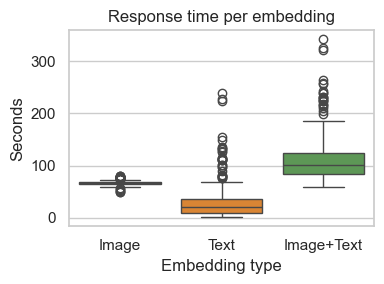

Exported overleaf\graphics\pixel_energy.pdf


C:\Users\Jonathan\AppData\Local\Temp\ipykernel_31016\4159158421.py:16: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(


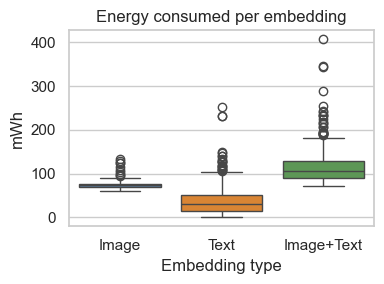

C:\Users\Jonathan\AppData\Local\Temp\ipykernel_31016\4159158421.py:16: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(


Exported overleaf\graphics\pixel_peak_rss.pdf


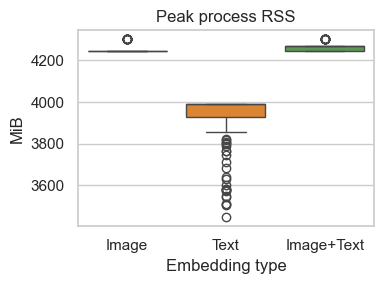

In [7]:
plot_specs = [
    ("response_time_s", "Response time per embedding", "Seconds",
     "pixel_response_time.pdf"),
    ("energy_mwh", "Energy consumed per embedding", "mWh",
     "pixel_energy.pdf"),
    ("peak_rss_mib", "Peak process RSS", "MiB",
     "pixel_peak_rss.pdf"),
]

plot_dir = Path("overleaf/graphics")
plot_dir.mkdir(parents=True, exist_ok=True)
palette = ["#4C78A8", "#F58518", "#54A24B"]
for column, title, ylabel, filename in plot_specs:
    fig, ax = plt.subplots(figsize=(4, 3))
    available = measurements.loc[measurements[column].notna()]
    sns.boxplot(
        data=available, x="embedding_type", y=column, order=EMBEDDING_ORDER,
        #hue="embedding_type",
        palette=palette, legend=False, showmeans=False,
        meanprops={"marker": "D", "markerfacecolor": "white",
                   "markeredgecolor": "black", "markersize": 5},
        ax=ax,
    )
    #sns.stripplot(
    #    data=available, x="embedding_type", y=column, order=EMBEDDING_ORDER,
    #    color="black", alpha=0.35, size=3, jitter=0.18, ax=ax,
    #)
    counts = available.groupby("embedding_type", observed=False)[column].count()
    ax.set_xticks(range(len(EMBEDDING_ORDER)))
    ax.set_xticklabels([kind.replace("+", "+").title() for kind in EMBEDDING_ORDER])
    ax.set_title(title)
    ax.set_xlabel("Embedding type")
    ax.set_ylabel(ylabel)
    fig.tight_layout()
    output_path = plot_dir / filename
    fig.savefig(output_path, format="pdf", bbox_inches="tight")
    print(f"Exported {output_path}")
    plt.show()


## Compact comparison and interpretation notes

In [8]:
comparison = (
    measurements.groupby("embedding_type", observed=False)
    .agg(
        n=("run_id", "size"),
        median_time_s=("response_time_s", "median"),
        median_energy_mwh=("energy_mwh", "median"),
        median_power_w=("average_power_w", "median"),
        memory_n=("peak_rss_mib", "count"),
        median_peak_rss_mib=("peak_rss_mib", "median"),
        median_rss_delta_mib=("rss_delta_mib", "median"),
    )
)
display(comparison.round(3))


,n,median_time_s,median_energy_mwh,median_power_w,memory_n,median_peak_rss_mib,median_rss_delta_mib
embedding_type,,,,,,,
image,285,65.682,73.560,3.964,140,4243.859,845.043
text,285,19.712,29.464,4.929,140,3989.686,606.425
image+text,285,101.090,104.762,3.721,140,4266.852,882.932


### Measurement cautions

- Battery energy comes from Android's counter (or, in these logs, charge-counter delta multiplied by mean voltage). Its finite resolution can make short requests especially noisy.
- Average power is calculated as measured energy divided by HTTP response time. It is whole-phone draw over that window, not an isolated accelerator/model rail measurement.
- `VmRSS`/`VmHWM` are kernel process-RSS estimates, not PSS or device-wide memory. `VmHWM` includes server/model startup plus the request, while `RSS after - RSS before` estimates the request-time resident increase.
- Memory boxplots and statistics use only logs where the fields exist. Always read `memory_n`; with one or two observations per type, those values are descriptive examples rather than stable distribution estimates.
- Input screens differ in image and cleaned-JSON complexity. These plots summarize the observed workload; they do not control for input token count or image complexity.

In [9]:
from itertools import combinations

import pandas as pd
from scipy import stats
from statsmodels.stats.multitest import multipletests

EMBEDDING_ORDER = ["image", "text", "image+text"]
METRICS = ["response_time_s", "energy_mwh", "peak_rss_mib"]

def friedman_then_pairwise_wilcoxon(measurements, metrics=METRICS):
  friedman_rows = []
  pairwise_rows = []

  for metric in metrics:
      # Friedman/Wilcoxon require paired observations: retain only runs
      # that have a value for all three embedding types for this metric.
      wide = (
          measurements.pivot(index="run_id", columns="embedding_type", values=metric)
          .reindex(columns=EMBEDDING_ORDER)
          .dropna()
      )

      friedman = stats.friedmanchisquare(
          *(wide[embedding] for embedding in EMBEDDING_ORDER)
      )
      friedman_rows.append({
          "metric": metric,
          "n_paired_runs": len(wide),
          "friedman_chi2": friedman.statistic,
          "friedman_p": friedman.pvalue,
      })

      for left, right in combinations(EMBEDDING_ORDER, 2):
          result = stats.wilcoxon(
              wide[left],
              wide[right],
              alternative="two-sided",
              zero_method="wilcox",
              method="auto",
          )
          pairwise_rows.append({
              "metric": metric,
              "comparison": f"{left} vs {right}",
              "n_paired_runs": len(wide),
              "median_difference": (wide[left] - wide[right]).median(),
              "wilcoxon_statistic": result.statistic,
              "p_raw": result.pvalue,
          })

  friedman_df = pd.DataFrame(friedman_rows)
  pairwise_df = pd.DataFrame(pairwise_rows)

  # Holm correction across the three pairwise comparisons within each metric.
  pairwise_df["p_holm"] = (
      pairwise_df.groupby("metric", group_keys=False)["p_raw"]
      .transform(lambda p: multipletests(p, method="holm")[1])
  )
  pairwise_df["significant_holm_0.05"] = pairwise_df["p_holm"] < 0.05

  return friedman_df, pairwise_df


friedman_results, wilcoxon_results = friedman_then_pairwise_wilcoxon(measurements)

display(friedman_results.round(4))
display(wilcoxon_results.round(4))

,metric,n_paired_runs,friedman_chi2,friedman_p
0,response_time_s,285,502.8281,0.0
1,energy_mwh,285,482.1684,0.0
2,peak_rss_mib,140,246.8730,0.0


,metric,comparison,n_paired_runs,median_difference,wilcoxon_statistic,p_raw,p_holm,significant_holm_0.05
0,response_time_s,image vs text,285,47.2080,4086.0,0.0,0.0,True
1,response_time_s,image vs image+text,285,-33.6070,15.0,0.0,0.0,True
2,response_time_s,text vs image+text,285,-82.8200,0.0,0.0,0.0,True
3,energy_mwh,image vs text,285,46.2510,3901.0,0.0,0.0,True
4,energy_mwh,image vs image+text,285,-30.6080,115.5,0.0,0.0,True
5,energy_mwh,text vs image+text,285,-76.2800,0.0,0.0,0.0,True
6,peak_rss_mib,image vs text,140,254.3435,0.0,0.0,0.0,True
7,peak_rss_mib,image vs image+text,140,-22.8520,481.5,0.0,0.0,True
8,peak_rss_mib,text vs image+text,140,-277.5620,0.0,0.0,0.0,True
